## <span style="color:purple"> Test Data: Graph Time Series Plots </span>

### <span style="color:purple"> Plotting function </span>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_time_series(df, am_id, ylim_temp=None, ylim_sal=None, resample=None):
    # Sort through dataframe keys and extract the keys containing the specified borehole is (AMXX)
    df_bh = df[df["borehole"] == am_id]
    cats = sorted(df_bh["cat"].unique(), key=int)
    
    if len(cats) == 0:
        print(f"No data for {am_id}")
        return

    fig, (axT, axS) = plt.subplots(2, 1, figsize=(12, 7), sharex=False)

    for cat_id in cats:
        dfp = df_bh[df_bh["cat"] == cat_id]

        # Optional: smooth/downsample to make multi-year plots readable
        # if resample is not None:
        #     dfp = df.resample(resample).mean(numeric_only=True)
        # else:
        #     dfp = df

        axT.plot(dfp["time"], dfp["in_situ_temperature"], lw=0.8, label=f"cat{cat_id}")
        axS.plot(dfp["time"], dfp["practical_salinity"],    lw=0.8, label=f"cat{cat_id}")

    axT.set_ylabel("In Situ Temperature (°C)")
    axS.set_ylabel("Practical Salinity (PSS78)")
    #axS.set_xlabel("Year")
    axT.set_title(f"{am_id} MicroCAT: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)

    axT.grid(True); axS.grid(True)
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Plot time series graphs of temp and salinity for each borehole location </span>

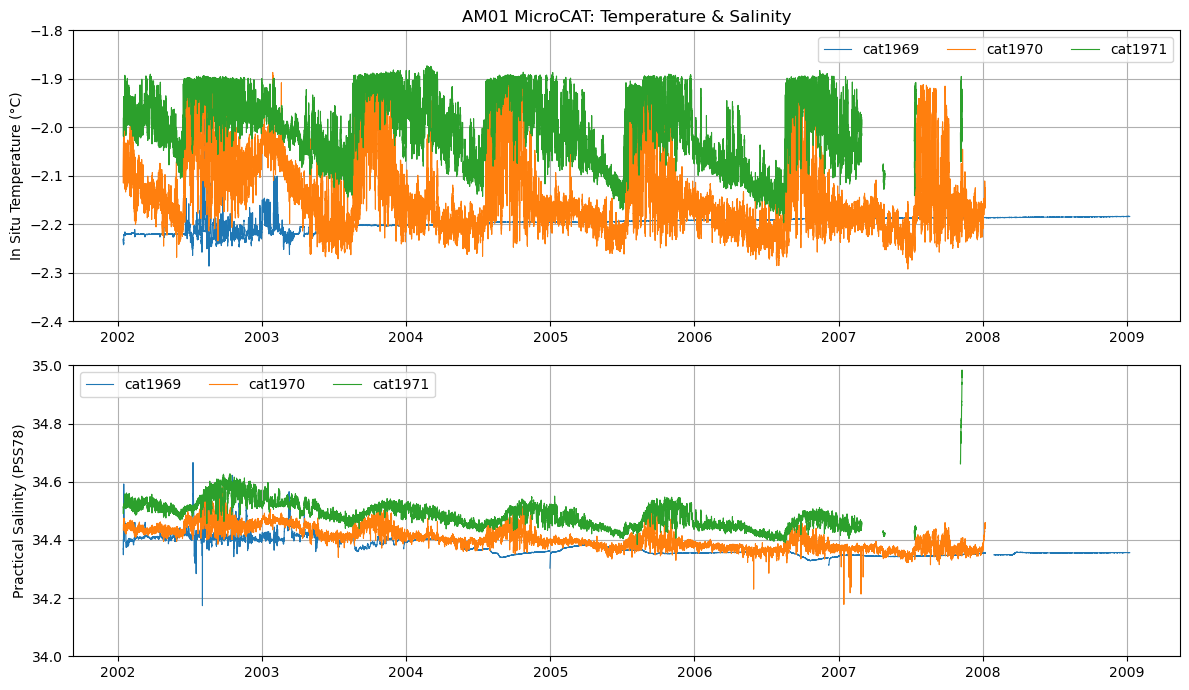

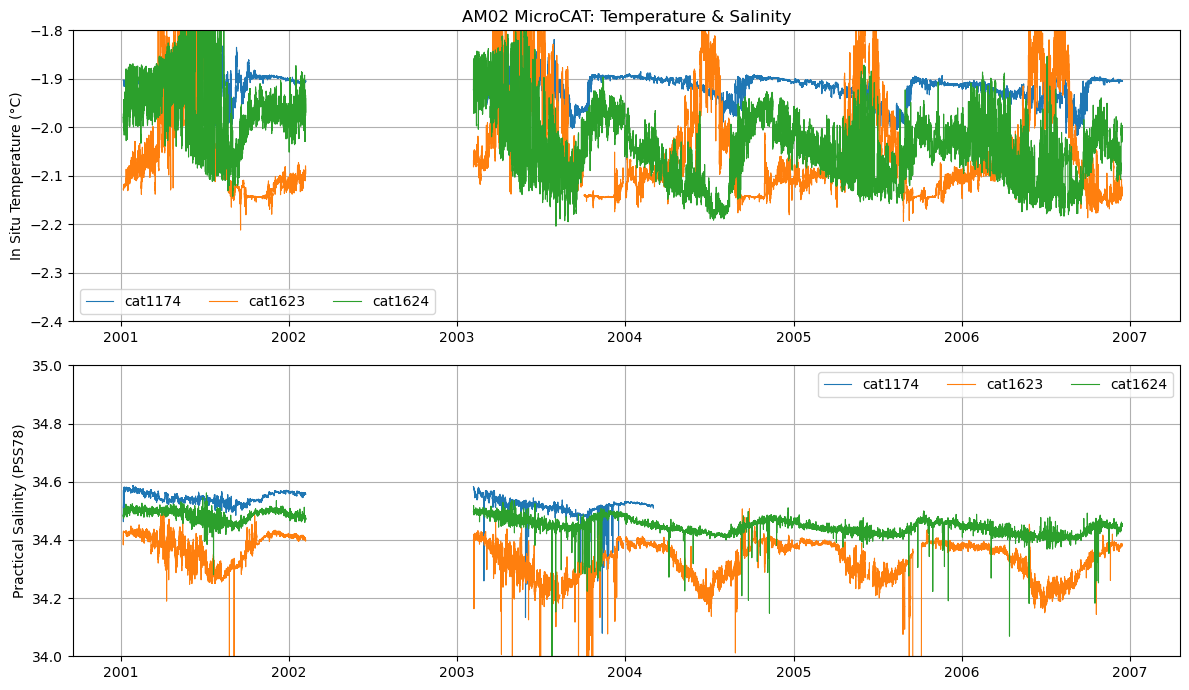

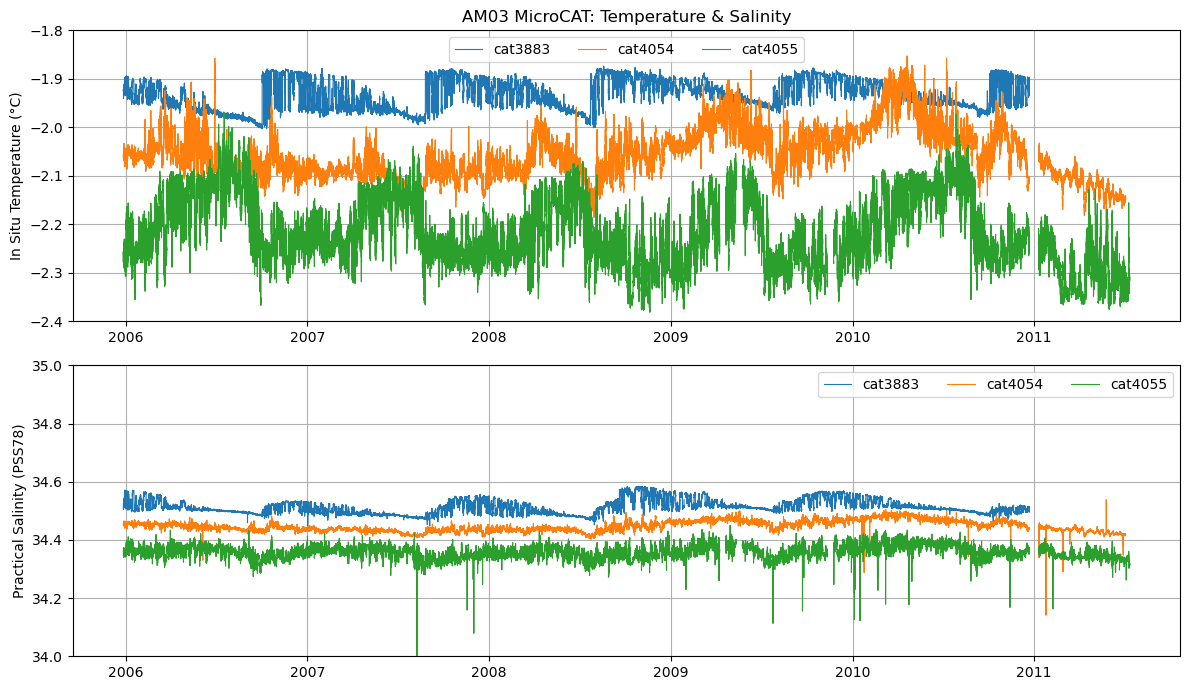

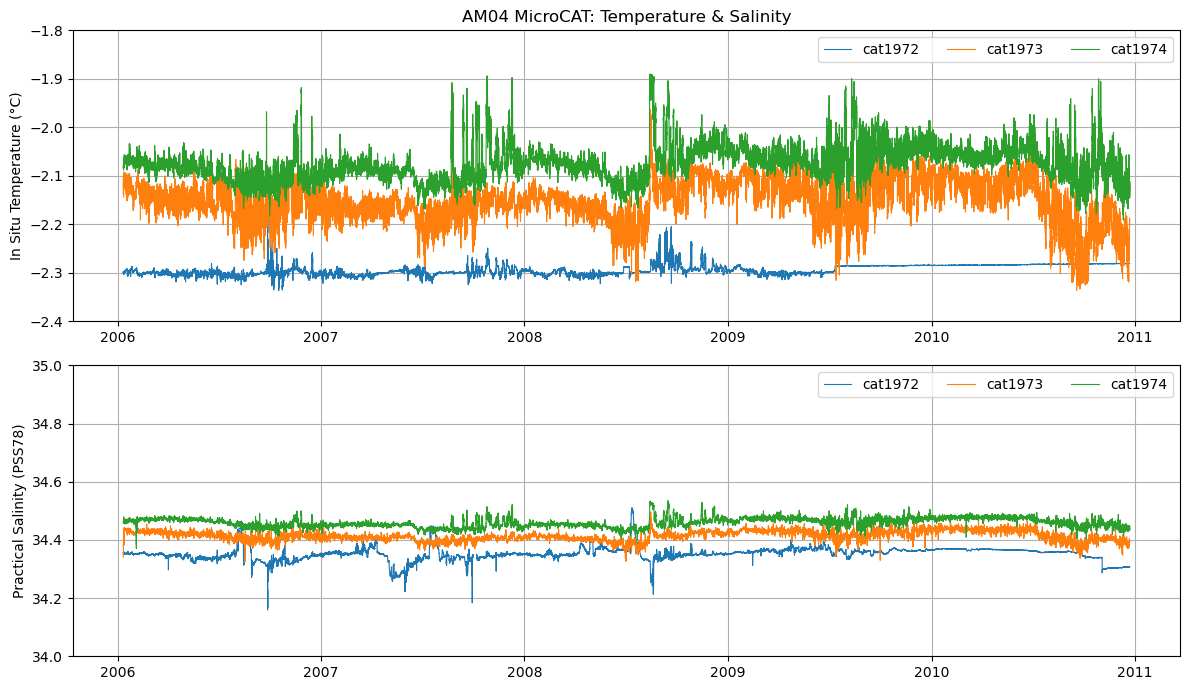

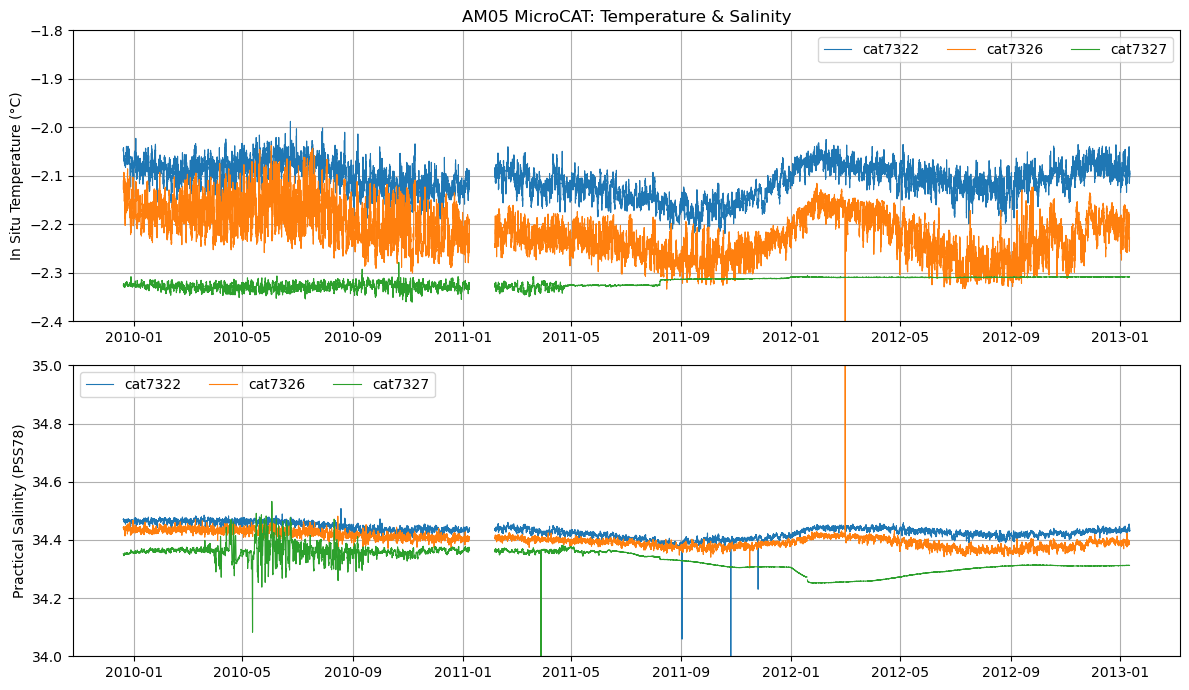

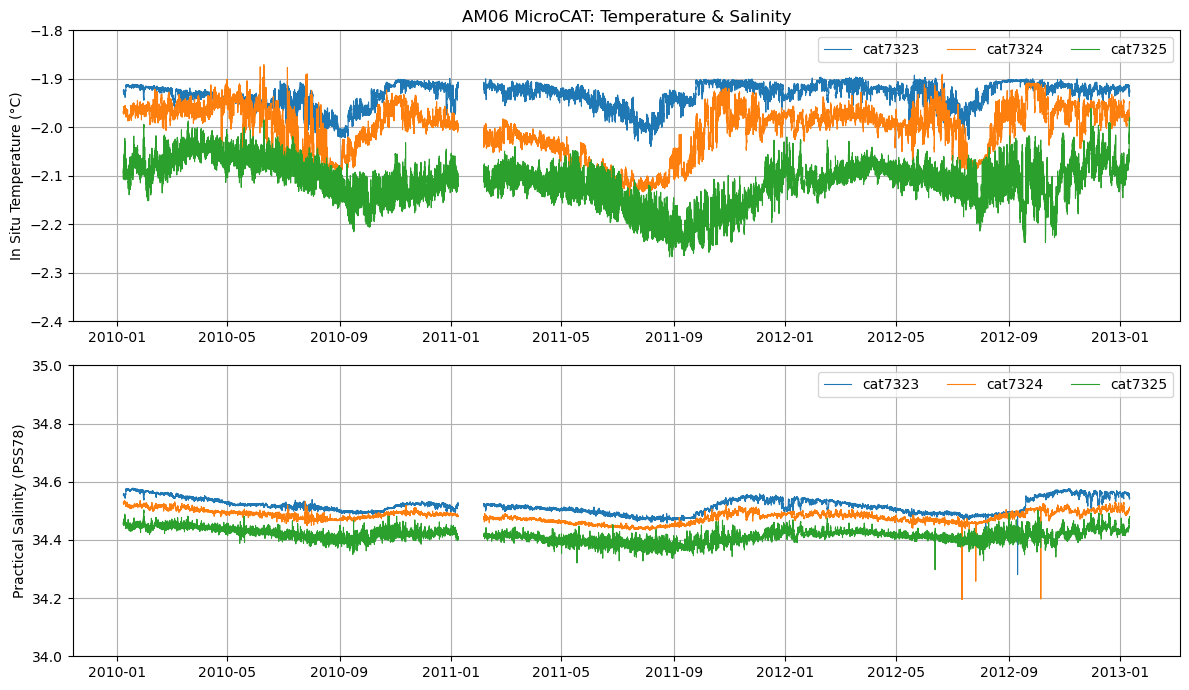

In [4]:
df = pd.read_parquet("../data/proc/01_imported.parquet")

# --- make one figure per borehole ---
boreholes = sorted(df["borehole"].unique())
for am_id in boreholes:
    plot_time_series(df, am_id, (-2.4, -1.8), (34, 35), resample="None")  # change "D" to None / "H" / "7D" etc.